# 01 · Load validation and cleaning

**Goal:** check the raw Olist tables for problems, decide how to handle each one, build a clean schema for analysis, and prove that the clean data reconciles with the raw data.

**Inputs:** the 9 raw tables loaded by `scripts/load_data.py`.
**Outputs:** the `clean` schema in Postgres (built by `sql/02b_build_clean_tables.sql`) and the data-quality log at the end of this notebook.

Each section follows the same pattern: **check → finding → decision**. The full set of SQL checks lives in `sql/02_data_quality_checks.sql`; this notebook runs the important ones and shows the evidence.

## 0. Setup

In [1]:
import os
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(REPO_ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])

def q(sql: str) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

# Chart style: one accent color for included data, gray for excluded,
# and ORANGE reserved for "late" in every chart of the project.
ACCENT, MUTED, LATE = "#2a78d6", "#b5b4ae", "#eb6834"
plt.rcParams.update({
    "figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Row counts

The loader already compared each table with its CSV. This is a second check from inside the database.

In [2]:
tables = ["orders", "order_items", "order_payments", "order_reviews", "customers",
          "products", "sellers", "category_translation", "geolocation"]
row_counts = pd.concat(
    [q(f"SELECT '{t}' AS table_name, COUNT(*) AS rows FROM {t}") for t in tables]
)
row_counts.style.format({"rows": "{:,}"}).hide(axis="index")

table_name,rows
orders,"99,441"
order_items,"112,650"
order_payments,"103,886"
order_reviews,"99,224"
customers,"99,441"
products,"32,951"
sellers,"3,095"
category_translation,71
geolocation,"1,000,163"


## 2. Missing values

`COUNT(*) - COUNT(col)` counts the NULLs in a column. The query below is generated for every column of the key tables, so no column gets missed.

In [3]:
def null_report(table: str) -> pd.DataFrame:
    cols = q(f"""
        SELECT column_name FROM information_schema.columns
        WHERE table_schema = 'public' AND table_name = '{table}'
        ORDER BY ordinal_position""")["column_name"]
    select = ", ".join(f"COUNT(*) - COUNT({c}) AS {c}" for c in cols)
    counts = q(f"SELECT COUNT(*) AS _total, {select} FROM {table}").iloc[0]
    total = counts.pop("_total")
    out = counts.rename("nulls").to_frame()
    out["pct"] = 100 * out["nulls"] / total
    out.insert(0, "table", table)
    return out[out["nulls"] > 0]

nulls = pd.concat([null_report(t) for t in ["orders", "order_reviews", "products"]])
nulls

,table,nulls,pct
order_approved_at,orders,160,0.16
order_delivered_carrier_date,orders,1783,1.79
order_delivered_customer_date,orders,2965,2.98
review_comment_title,order_reviews,87658,88.34
review_comment_message,order_reviews,58274,58.73
product_category_name,products,610,1.85
product_name_length,products,610,1.85
product_description_length,products,610,1.85
product_photos_qty,products,610,1.85
product_weight_g,products,2,0.01


**Finding.**
- The missing timestamps in `orders` belong mostly to orders that never reached that stage: canceled, unavailable or still shipping.
- Review text is missing for most reviews, which is expected because comments are optional.
- 610 products have no category.

**Decision.**
- Delivery metrics are calculated only for delivered orders.
- Products with no category are labeled `unknown`.
- Review text is not used in this analysis (noted as a limitation).

## 3. Order status: which orders count?

In [4]:
status = q("""
    SELECT order_status, COUNT(*) AS orders,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM orders GROUP BY 1 ORDER BY 2 DESC""")
status

,order_status,orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [5]:
q("""
    SELECT
        COUNT(*) FILTER (WHERE order_status = 'delivered'
                         AND order_delivered_customer_date IS NULL)     AS delivered_but_no_date,
        COUNT(*) FILTER (WHERE order_status <> 'delivered'
                         AND order_delivered_customer_date IS NOT NULL) AS has_date_but_not_delivered
    FROM orders""")

,delivered_but_no_date,has_date_but_not_delivered
0,8,6


**Finding.** 97% of orders are `delivered`. The status and the delivery date disagree for 14 orders.

**Decision.** An order counts as delivered only when the status is `delivered` **and** it has a delivered date (`is_delivered` in the clean table). Revenue, delivery and review metrics use delivered orders only. All other statuses stay in `clean.orders` so cancellation rates can still be studied.

## 4. Partial months: choosing the analysis window

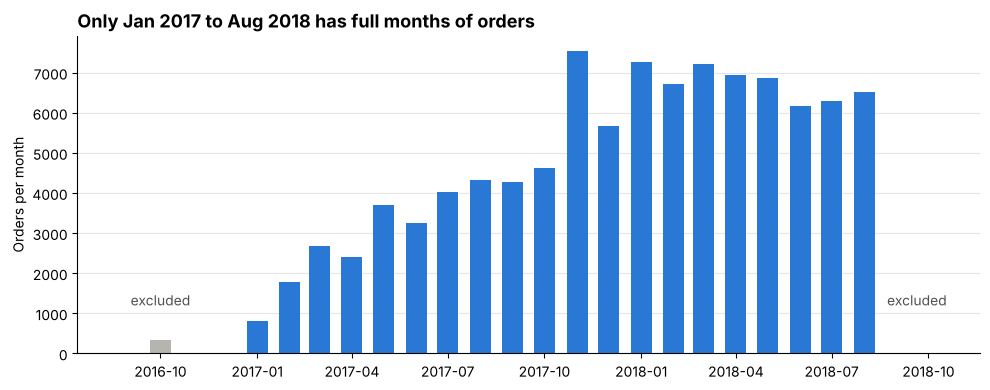

,month,orders,in_window
0,2016-09-01,4,False
1,2016-10-01,324,False
2,2016-12-01,1,False
23,2018-09-01,16,False
24,2018-10-01,4,False


In [6]:
monthly = q("""
    SELECT DATE_TRUNC('month', order_purchase_timestamp)::date AS month, COUNT(*) AS orders
    FROM orders GROUP BY 1 ORDER BY 1""")
monthly["month"] = pd.to_datetime(monthly["month"])
monthly["in_window"] = monthly["month"].between("2017-01-01", "2018-08-01")

fig, ax = plt.subplots()
ax.bar(monthly["month"], monthly["orders"], width=20,
       color=monthly["in_window"].map({True: ACCENT, False: MUTED}))
ax.set_title("Only Jan 2017 to Aug 2018 has full months of orders")
ax.set_ylabel("Orders per month")
ax.text(pd.Timestamp("2016-10-01"), 1200, "excluded", color="#52514e", ha="center")
ax.text(pd.Timestamp("2018-09-20"), 1200, "excluded", color="#52514e", ha="center")
plt.tight_layout(); plt.show()

monthly[~monthly["in_window"]]

**Finding.**
- Sep–Dec 2016 has 329 orders in total and no orders at all in November.
- Sep–Oct 2018 has only 20 orders, because the data export stopped there.
- Kept in the charts, these months would show fake crashes in growth.

**Decision.** The analysis window is **2017-01-01 to 2018-08-31**, which is 20 full months. This removes 349 orders (0.35%).

## 5. Impossible timestamps

In [7]:
q("""
    SELECT
        COUNT(*) FILTER (WHERE order_delivered_customer_date < order_purchase_timestamp)     AS delivered_before_purchase,
        COUNT(*) FILTER (WHERE order_approved_at < order_purchase_timestamp)                 AS approved_before_purchase,
        COUNT(*) FILTER (WHERE order_delivered_carrier_date < order_purchase_timestamp)      AS carrier_before_purchase,
        COUNT(*) FILTER (WHERE order_delivered_customer_date < order_delivered_carrier_date) AS customer_before_carrier
    FROM orders""")

,delivered_before_purchase,approved_before_purchase,carrier_before_purchase,customer_before_carrier
0,0,0,166,23


**Finding.** No order was delivered before it was purchased. 166 orders show the carrier picking up the parcel before the customer bought it, which is impossible and most likely a data-entry error.

**Decision.** Those carrier dates are set to NULL in the clean table. The customer delivery date, which is the one used for lateness, is unaffected.

## 6. Defining "late"

The estimated delivery date has no time of day. Every value is midnight, so comparing timestamps would call an order late even when it arrived during the promised day.

In [8]:
q("""
    SELECT
        COUNT(DISTINCT order_estimated_delivery_date::time) AS distinct_estimate_times,
        COUNT(*) FILTER (WHERE order_delivered_customer_date > order_estimated_delivery_date) AS late_by_timestamp,
        COUNT(*) FILTER (WHERE order_delivered_customer_date::date
                               > order_estimated_delivery_date::date)                         AS late_by_calendar_day
    FROM orders WHERE order_status = 'delivered'""")

,distinct_estimate_times,late_by_timestamp,late_by_calendar_day
0,1,7826,6534


**Finding.** The timestamp comparison would count 1,292 extra orders as late (7,826 vs. 6,534), about 20% more than the calendar-day comparison.

**Decision.** **Late = delivered on a later calendar day than the estimated date.** The same rule is used everywhere in the project.

## 7. Duplicate reviews

In [9]:
q("""
    SELECT COUNT(*) AS review_rows,
           COUNT(DISTINCT review_id) AS distinct_review_ids,
           COUNT(DISTINCT order_id)  AS distinct_orders,
           (SELECT COUNT(*) FROM (SELECT order_id FROM order_reviews
                                  GROUP BY 1 HAVING COUNT(*) > 1) m) AS orders_with_2plus_reviews
    FROM order_reviews""")

,review_rows,distinct_review_ids,distinct_orders,orders_with_2plus_reviews
0,99224,98410,98673,547


**Finding.** `review_id` is not unique: one review can be attached to several orders, and 547 orders have two or more reviews. If both review rows were joined to an order, that order would count twice in the averages.

**Decision.** Keep the **latest** review per order, ranked with `ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC)`.

## 8. Orders without items, payments, or reviews

In [10]:
q("""
    SELECT o.order_status, COUNT(*) AS orders_without_items
    FROM orders o
    WHERE NOT EXISTS (SELECT 1 FROM order_items i WHERE i.order_id = o.order_id)
    GROUP BY 1 ORDER BY 2 DESC""")

,order_status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


**Finding.** 775 orders have no items, and nearly all of them are `unavailable` or `canceled`: the order was placed but never fulfilled. One order has no payment record, and 768 have no review.

**Decision.** These orders are kept in `clean.orders` with NULL values. They are not deleted, so the cancellation rate stays correct, and they drop out of revenue calculations naturally.

## 9. Do payments match item totals?

**Row multiplication trap:** joining `order_items` (3 items) to `order_payments` (2 payments) gives 6 rows per order and inflates both totals. Each table is summed to one row per order in its own CTE *before* the join.

In [11]:
q("""
    WITH item_totals AS (
        SELECT order_id, SUM(price + freight_value) AS items_total
        FROM order_items GROUP BY order_id),
    payment_totals AS (
        SELECT order_id, SUM(payment_value) AS payment_total
        FROM order_payments GROUP BY order_id)
    SELECT COUNT(*) AS orders_compared,
           COUNT(*) FILTER (WHERE ABS(items_total - payment_total) > 0.01) AS differ_by_over_1_cent,
           COUNT(*) FILTER (WHERE ABS(items_total - payment_total) > 1)    AS differ_by_over_1_real
    FROM item_totals JOIN payment_totals USING (order_id)
    JOIN orders o USING (order_id) WHERE o.order_status = 'delivered'""")

,orders_compared,differ_by_over_1_cent,differ_by_over_1_real
0,96477,362,309


**Finding.** 99.6% of delivered orders match to the cent. The 362 that don't are mostly explained by vouchers and installment interest.

**Decision.** **Revenue is always measured from `order_items.price`**, never from payments. Payments are used only for the payment-method analysis. The 3 `not_defined` payment rows, all worth R$0, are dropped.

## 10. Category translation

In [12]:
q("""
    SELECT p.product_category_name, COUNT(*) AS items
    FROM order_items i JOIN products p USING (product_id)
    LEFT JOIN category_translation t USING (product_category_name)
    WHERE p.product_category_name IS NOT NULL AND t.product_category_name IS NULL
    GROUP BY 1""")

,product_category_name,items
0,portateis_cozinha_e_preparadores_de_alimentos,15
1,pc_gamer,9


**Finding.** Two Portuguese categories (24 items) are missing from the translation table.

**Decision.** Translate them by hand: `pc_gamer` stays `pc_gamer`, and `portateis_cozinha_e_preparadores_de_alimentos` becomes `portable_kitchen_and_food_preparers`. The 610 products with no category are labeled `unknown`.

## 11. Geolocation duplicates

In [13]:
q("""
    SELECT COUNT(*) AS geo_rows,
           COUNT(DISTINCT geolocation_zip_code_prefix) AS distinct_zips,
           COUNT(*) FILTER (WHERE geolocation_lat NOT BETWEEN -34 AND 5.5
                               OR geolocation_lng NOT BETWEEN -74 AND -34) AS outside_brazil
    FROM geolocation""")

,geo_rows,distinct_zips,outside_brazil
0,1000163,19015,42


**Finding.** There are about 1M rows for only 19,015 zip prefixes, roughly 53 rows per zip. Joining this table directly would multiply every order about 53 times. 42 points lie outside Brazil.

**Decision.** Build one row per zip by averaging the coordinates of the points inside Brazil's bounding box.

## 12. Build the clean schema

All of the decisions above are implemented in one re-runnable SQL file. Keeping them in SQL, rather than pandas, means the clean tables live in the database where the analysis queries can use them.

In [14]:
build_sql = (REPO_ROOT / "sql" / "02b_build_clean_tables.sql").read_text(encoding="utf-8")
with engine.begin() as conn:
    conn.exec_driver_sql(build_sql)

clean_tables = ["orders", "order_items", "order_payments", "order_reviews",
                "order_summary", "products", "sellers", "geolocation"]
pd.concat([q(f"SELECT 'clean.{t}' AS table_name, COUNT(*) AS rows FROM clean.{t}")
           for t in clean_tables]).style.format({"rows": "{:,}"}).hide(axis="index")

table_name,rows
clean.orders,"99,092"
clean.order_items,"112,279"
clean.order_payments,"103,518"
clean.order_reviews,"98,330"
clean.order_summary,"99,092"
clean.products,"32,951"
clean.sellers,"3,095"
clean.geolocation,"19,010"


## 13. Validate the clean tables

Cleaning can introduce bugs of its own, so these tests prove it didn't. Each `assert` stops the notebook if a rule is broken.

In [15]:
checks = q("""
    SELECT
      -- 1. One row per order in the summary (no row multiplication)
      (SELECT COUNT(*) FROM clean.order_summary) = (SELECT COUNT(*) FROM clean.orders)        AS summary_one_row_per_order,
      -- 2. Exactly one review per order
      (SELECT COUNT(*) = COUNT(DISTINCT order_id) FROM clean.order_reviews)                  AS one_review_per_order,
      -- 3. Revenue in the clean tables equals raw revenue for the same window, to the cent
      (SELECT SUM(price) FROM order_items i JOIN orders o USING (order_id)
        WHERE o.order_purchase_timestamp >= '2017-01-01'
          AND o.order_purchase_timestamp <  '2018-09-01')
        = (SELECT SUM(items_value) FROM clean.order_summary)                                 AS revenue_reconciles,
      -- 4. Every order falls inside the analysis window
      (SELECT MIN(purchase_ts) >= '2017-01-01' AND MAX(purchase_ts) < '2018-09-01'
         FROM clean.orders)                                                                  AS window_respected,
      -- 5. Delivery metrics exist only for delivered orders, and are never negative
      (SELECT COUNT(*) = 0 FROM clean.orders
        WHERE (is_delivered AND (delivery_days IS NULL OR delivery_days < 0))
           OR (NOT is_delivered AND is_late IS NOT NULL))                                    AS delivery_metrics_consistent,
      -- 6. No item lost its category
      (SELECT COUNT(*) = 0 FROM clean.order_items WHERE category IS NULL)                    AS every_item_has_category,
      -- 7. One row per zip code
      (SELECT COUNT(*) = COUNT(DISTINCT zip_code_prefix) FROM clean.geolocation)             AS one_row_per_zip
""").T.rename(columns={0: "passed"})

assert checks["passed"].all(), checks[~checks["passed"]]
checks

,passed
summary_one_row_per_order,True
one_review_per_order,True
revenue_reconciles,True
window_respected,True
delivery_metrics_consistent,True
every_item_has_category,True
one_row_per_zip,True


## 14. First look: the clean numbers

A quick sanity check of the headline metrics, using the definitions in the README. The full analysis comes in the SQL files and `02_analysis_and_stats.ipynb`.

In [16]:
headline = q("""
    SELECT
        SUM(items_value)                                  AS revenue_brl,
        COUNT(*)                                          AS delivered_orders,
        SUM(items_value) / COUNT(*)                       AS aov_brl,
        COUNT(DISTINCT customer_unique_id)                AS unique_customers,
        100.0 * AVG(is_late::int)                         AS late_rate_pct,
        AVG(review_score)                                 AS avg_review,
        AVG(review_score) FILTER (WHERE NOT is_late)      AS avg_review_on_time,
        AVG(review_score) FILTER (WHERE is_late)          AS avg_review_late
    FROM clean.order_summary
    WHERE is_delivered""").T.rename(columns={0: "value"})
headline

,value
revenue_brl,"13,179,777.95"
delivered_orders,"96,203.00"
aov_brl,137.00
unique_customers,"93,096.00"
late_rate_pct,6.79
avg_review,4.16
avg_review_on_time,4.29
avg_review_late,2.27


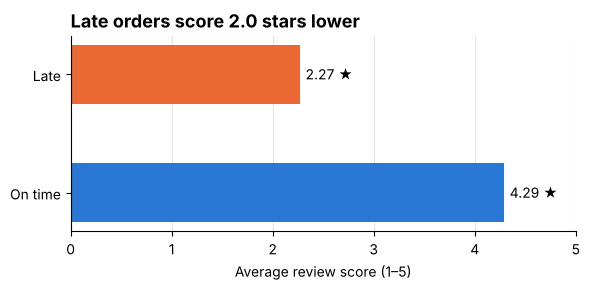

In [17]:
scores = q("""
    SELECT CASE WHEN is_late THEN 'Late' ELSE 'On time' END AS delivery,
           AVG(review_score) AS avg_review, COUNT(*) AS orders
    FROM clean.order_summary
    WHERE is_delivered AND review_score IS NOT NULL
    GROUP BY 1 ORDER BY 1 DESC""")

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.barh(scores["delivery"], scores["avg_review"],
               color=scores["delivery"].map({"On time": ACCENT, "Late": LATE}), height=0.5)
ax.bar_label(bars, fmt="%.2f ★", padding=4)
ax.set_xlim(0, 5); ax.set_xlabel("Average review score (1–5)")
ax.grid(axis="x", color="#e6e5e1"); ax.grid(axis="y", visible=False)
gap = scores.set_index("delivery")["avg_review"]
ax.set_title(f"Late orders score {gap['On time'] - gap['Late']:.1f} stars lower")
plt.tight_layout(); plt.show()

This early result is the project's likely headline. Phase 4 tests whether the gap is statistically significant and reports its effect size.

## 15. Data-quality log

In [18]:
log = pd.DataFrame([
    ("Customer and seller zip prefixes lost leading zeros in the source CSVs", "23,995 customers; 1,027 sellers", "Zero-padded to 5 digits at load", "load_data.py"),
    ("Customer zips with no geolocation match (after padding)", "279 customers", "Kept; shown as unknown on maps", "n/a"),
    ("Misspelled source columns (product_*_lenght)", "2 columns", "Renamed to *_length at load", "load_data.py"),
    ("Byte-order mark in category translation CSV", "1 file", "Read with utf-8-sig", "load_data.py"),
    ("Partial months at start (2016) and end (Sep–Oct 2018)", "349 orders", "Window = 2017-01-01 to 2018-08-31", "02b · clean.orders"),
    ("Order status and delivered date disagree", "14 orders", "Delivered = status AND date present", "02b · is_delivered"),
    ("Carrier pickup recorded before purchase", "166 orders", "Carrier date set to NULL", "02b · carrier_ts"),
    ("Estimated delivery is date-only, so timestamp comparison overstates lateness", "1,292 orders", "Late compared by calendar day", "02b · is_late"),
    ("Orders with several reviews; review_id reused across orders", "547 orders", "Kept latest review per order", "02b · clean.order_reviews"),
    ("Reviews written before the order arrived", "5,126 orders", "Kept; noted as a limitation", "n/a"),
    ("Orders with no items (unavailable / canceled)", "775 orders", "Kept with NULL values", "02b · clean.order_summary"),
    ("Payments differ from items + freight", "362 orders", "Revenue taken from order_items only", "README metric definitions"),
    ("'not_defined' payment type, all R$0", "3 rows", "Dropped", "02b · clean.order_payments"),
    ("Products with no category", "610 products (1,603 items)", "Labeled 'unknown'", "02b · clean.products"),
    ("Categories missing from translation table", "2 categories (24 items)", "Translated by hand", "02b · clean.products"),
    ("Geolocation: ~53 rows per zip prefix; 42 points outside Brazil", "1,000,163 rows", "1 row per zip, averaged inside Brazil", "02b · clean.geolocation"),
], columns=["issue", "rows_affected", "fix", "where"])
log.index = log.index + 1
log

,issue,rows_affected,fix,where
1,Customer and seller zip prefixes lost leading ...,"23,995 customers; 1,027 sellers",Zero-padded to 5 digits at load,load_data.py
2,Customer zips with no geolocation match (after...,279 customers,Kept; shown as unknown on maps,n/a
3,Misspelled source columns (product_*_lenght),2 columns,Renamed to *_length at load,load_data.py
4,Byte-order mark in category translation CSV,1 file,Read with utf-8-sig,load_data.py
5,Partial months at start (2016) and end (Sep–Oc...,349 orders,Window = 2017-01-01 to 2018-08-31,02b · clean.orders
6,Order status and delivered date disagree,14 orders,Delivered = status AND date present,02b · is_delivered
7,Carrier pickup recorded before purchase,166 orders,Carrier date set to NULL,02b · carrier_ts
8,"Estimated delivery is date-only, so timestamp ...","1,292 orders",Late compared by calendar day,02b · is_late
9,Orders with several reviews; review_id reused ...,547 orders,Kept latest review per order,02b · clean.order_reviews
10,Reviews written before the order arrived,"5,126 orders",Kept; noted as a limitation,n/a
